# FT-Transformer — Employee Resignation Prediction

**Member 1 model:** FT-Transformer  
**Task:** Binary classification  
**Target:** `Resigned` (`1` = resigned)  
**Primary metric:** Average Precision / PR-AUC

## Objective

Evaluate FT-Transformer on the project's **80,000-row development partition** using the frozen **5-fold cross-validation** registry and all **17 approved predictors**.

The **20,000-row formal holdout remains locked**. It is excluded from preprocessing, class-weight calculation, inner validation, early stopping, hyperparameter screening, model selection, threshold analysis, and OOF evaluation.

**Completed scope:** fixed weighted FT02 evaluated across five development folds on GPU. Inner validation selects the epoch count; a fresh model then fits only the inner-training rows. Earlier controlled screening is supporting historical evidence. The eight-candidate configuration is an optional extension and was not executed.

## Individual variation evidence

The full five-fold weighted OOF result remains the group input. The table below is a **short exploratory input check**: the same 5,000 development training rows and 2,000 held-out rows from outer fold 1, five epochs, with salary kept or replaced by the **training-only median**. FT01/FT02 share their architecture and learning rate; FT02 uses fold-local positive-class weighting. Outer scores did not select the group configuration.

| Input preparation | FT01 AP, unweighted | FT02 AP, weighted |
|---|---:|---:|
| All 17 predictors | 0.101889 | 0.102254 |
| Salary masked at training median | 0.096129 | 0.101808 |

Neither input change establishes a reliable gain on this small sample. The full metric/validation table and other members' results are in [Individual model evidence](../../../../reports/INDIVIDUAL_MODEL_EVIDENCE.md). The reproducible check is `scripts/run_preprocessing_sensitivity.py`; it does not overwrite this notebook's historical weighted OOF files.


## Methodology and Leakage Controls

Each outer fold uses **64,000 outer-training rows** and **16,000 untouched outer-validation rows**. A stratified 15% inner-validation split leaves **54,400 inner-training rows** and **9,600 inner-validation rows**.

For the fixed FT02 candidate, the selection stage fits numerical standardization and categorical mappings on inner-training rows only, reserving category index `0` for missing/unknown values. Its positive-class weight is the inner-training negative/positive ratio. AdamW and weighted BCE train the selection model; inner-validation AP drives `ReduceLROnPlateau` and early stopping (patience 15, maximum 100 epochs).

The selected epoch count is passed to a **fresh model**, with preprocessing and class weight fitted again on the same inner-training rows. This final fit runs for that epoch count with a fresh AdamW optimizer, **without a scheduler or further validation**. Selection-model weights are not used for outer-fold predictions. With `refit_outer_train=False`, the inner-validation rows are not added to this final fit; this differs from the config-driven full outer-training refit mode.

A fresh adapter is created for each outer fold. `Employee_ID`, `Hire_Date` and `Resigned` are excluded from predictors. The shared runner rejects formal-holdout IDs. Historical screening was not repeated independently within every fold, so this is not a nested eight-candidate search.

In [1]:
# -----------------------------
# 1. Imports and project setup
# -----------------------------

import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display
from sklearn.metrics import precision_recall_curve

# Resolve the repository root from notebooks/team_contributions/models/member_1_ft_transformer/.
def find_project_root(start_path: Path | None = None) -> Path:
    """Locate the repository root from any notebook launch directory."""
    start = (start_path or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "configs" / "feature_contract.yaml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate repository root containing configs/feature_contract.yaml")

PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.metrics import calculate_binary_metrics
from src.models.ft_transformer import FTTransformerAdapter
from src.models.runner import run_5fold_cv

pd.set_option("display.max_columns", None)

CONFIG_PATH = PROJECT_ROOT / "configs" / "models" / "ft_transformer.yaml"
FEATURE_CONTRACT_PATH = PROJECT_ROOT / "configs" / "feature_contract.yaml"
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Extended_Employee_Performance_and_Productivity_Data.csv"
SPLIT_PATH = PROJECT_ROOT / "data" / "processed" / "split_registry.csv"
RESULTS_DIR = PROJECT_ROOT / "results" / "models" / "ft_transformer"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

required_paths = [CONFIG_PATH, FEATURE_CONTRACT_PATH, DATA_PATH, SPLIT_PATH]
missing_paths = [str(path) for path in required_paths if not path.exists()]
assert not missing_paths, f"Missing required project files: {missing_paths}"

print("Project root:", PROJECT_ROOT)
print("Results directory:", RESULTS_DIR)


Project root: D:\Employee_Resignation_Prediction
Results directory: D:\Employee_Resignation_Prediction\results\models\ft_transformer


In [2]:
# 2. Load the fixed FT02 parameters and the explicitly selected canonical run
with open(CONFIG_PATH, "r", encoding="utf-8") as file:
    ft_config = yaml.safe_load(file)
with open(FEATURE_CONTRACT_PATH, "r", encoding="utf-8") as file:
    feature_contract = yaml.safe_load(file)

model_name = ft_config["model"]["name"]
model_id = ft_config["model"]["model_id"]
fixed_params = ft_config["fixed_params"].copy()
# The current config uses an explicit candidate registry rather than a legacy search_space block.
# FT02 has the historical architecture AND the required dynamic class weighting.
ft02 = next(c for c in ft_config["candidates"] if c["id"] == "FT02")
final_run_params = {**fixed_params, **ft02["params"], "validation_fraction_inner": ft_config["inner_validation"]["fraction"], "max_epochs": ft_config["inner_validation"]["max_epochs"], "patience": ft_config["inner_validation"]["patience"], "seed": ft_config["reproducibility"]["seed"]}
assert final_run_params["weighting"] == "dynamic_ratio"
historical_config = json.loads((RESULTS_DIR / "weighted_early_stopping_final" / "ft_transformer_final_configuration.json").read_text(encoding="utf-8"))
assert all(final_run_params[key] == value for key, value in historical_config.items()), "FT02 diverges from the recorded historical architecture"
config_summary = pd.DataFrame([(k,v) for k,v in final_run_params.items()], columns=["Setting","Value"])
display(config_summary)
analysis_registry = yaml.safe_load((PROJECT_ROOT / "configs" / "analysis_registry.yaml").read_text(encoding="utf-8"))
CANONICAL_FT_DIR = (PROJECT_ROOT / analysis_registry["models"][model_name]["oof_path"]).parent
CANONICAL_FT_RUN_ID = CANONICAL_FT_DIR.name
assert CANONICAL_FT_RUN_ID == "FT02_20261003T025004Z", "Review the selected run before adopting different evidence"
print("Completed candidate: FT02; optional candidate registry:", [c["id"] for c in ft_config["candidates"]])
print("Canonical completed run:", CANONICAL_FT_RUN_ID)

,Setting,Value
0,optimizer,AdamW
1,weighting,dynamic_ratio
2,weight_decay,0.00001
3,attention_dropout,0.1
4,residual_dropout,0.0
5,batch_size,512
6,seed,42
7,max_epochs,100
8,patience,15
9,lr_scheduler,ReduceLROnPlateau


Completed candidate: FT02; optional candidate registry: ['FT01', 'FT02', 'FT03', 'FT04', 'FT05', 'FT06', 'FT07', 'FT08']
Canonical completed run: FT02_20261003T025004Z


## GPU training setup

For a new FT02 five-fold run, select a Jupyter kernel with CUDA-enabled PyTorch and restart the kernel. The next cell reports the exact Python executable and checks a CUDA tensor operation. A working NVIDIA driver alone does not make a CPU-only PyTorch build GPU-capable.

Set `RUN_FT_TRAINING = True` in the evaluation cell only when ready to train. With `REQUIRE_GPU_FOR_TRAINING = True`, a deliberate rerun stops before fitting or creating a run directory if CUDA is unavailable. The adapter uses CUDA device 0 automatically; no additional GPU training library is needed. The batch size and training protocol remain those of the configured FT02 experiment.

The default `RUN_FT_TRAINING = False` loads the canonical completed GPU run and can execute on a CPU kernel. A new GPU run writes to a unique timestamped directory; its metrics may differ from the historical run. This launches the single FT02 experiment, not the eight-candidate nested search.

In [3]:
# 3. Reproducibility and GPU readiness
# The adapter automatically uses CUDA when available. GPU training is required
# for deliberate reruns in this notebook; saved evidence can load on any machine.
REQUIRE_GPU_FOR_TRAINING = True

print("Python kernel:", sys.executable)
print("PyTorch version:", torch.__version__)
print("PyTorch CUDA runtime:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    torch.cuda.set_device(0)
    device = torch.device("cuda:0")
    device_label = torch.cuda.get_device_name(0)
    # Exercise allocation, a CUDA operation and synchronization before training.
    probe = torch.ones(4, device=device)
    assert float((probe * 2).sum().item()) == 8.0
    torch.cuda.synchronize()
    del probe
    print("GPU readiness check passed:", device_label)
    print("GPU memory:", f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")
else:
    device = torch.device("cpu")
    device_label = "CPU"
    print("GPU training is not ready in this kernel. Saved results can still be inspected.")
    if torch.version.cuda is None:
        print("This is a CPU-only PyTorch build. Use a kernel with CUDA-enabled PyTorch, then restart and run all.")
    else:
        print("CUDA-enabled PyTorch is installed, but CUDA is unavailable. Check the NVIDIA driver and kernel environment.")

print("Random seed:", fixed_params["seed"])


Python kernel: C:\Python314\python.exe
PyTorch version: 2.13.0+cu130
PyTorch CUDA runtime: 13.0
CUDA available: True


GPU readiness check passed: NVIDIA GeForce RTX 4060 Laptop GPU
GPU memory: 8.00 GB
Random seed: 42


In [4]:
# -----------------------------
# 4. Load raw data and frozen split registry
# -----------------------------

df = pd.read_csv(DATA_PATH)
split_registry = pd.read_csv(SPLIT_PATH)

assert df.shape == (100_000, 20), f"Unexpected raw dataset shape: {df.shape}"
assert split_registry.shape == (100_000, 3), (
    f"Unexpected split-registry shape: {split_registry.shape}"
)
assert df["Employee_ID"].is_unique
assert split_registry["Employee_ID"].is_unique

print("Raw dataset shape:", df.shape)
print("Split registry shape:", split_registry.shape)
print("\nPartition counts:")
print(split_registry["partition"].value_counts())


Raw dataset shape: (100000, 20)
Split registry shape: (100000, 3)

Partition counts:
partition
development    80000
holdout        20000
Name: count, dtype: int64


In [5]:
# -----------------------------
# 5. Isolate the development partition and enforce holdout protection
# -----------------------------

development_ids = set(
    split_registry.loc[
        split_registry["partition"] == "development",
        "Employee_ID",
    ]
)
holdout_ids = set(
    split_registry.loc[
        split_registry["partition"] == "holdout",
        "Employee_ID",
    ]
)

development_data = (
    df.loc[df["Employee_ID"].isin(development_ids)]
    .copy()
    .reset_index(drop=True)
)

development_df = development_data.merge(
    split_registry[["Employee_ID", "partition", "cv_fold"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one",
)
development_df["cv_fold"] = development_df["cv_fold"].astype(int)

assert len(development_data) == 80_000
assert "cv_fold" not in development_data.columns
assert "partition" not in development_data.columns
assert len(holdout_ids) == 20_000
assert set(development_data["Employee_ID"]).isdisjoint(holdout_ids)
assert set(development_df["cv_fold"].unique()) == {1, 2, 3, 4, 5}
assert development_df["cv_fold"].value_counts().eq(16_000).all()

print("Development rows:", len(development_data))
print("Formal holdout rows excluded:", len(holdout_ids))
print("Holdout IDs present in modeling data: 0")
print("\nDevelopment fold counts:")
print(development_df["cv_fold"].value_counts().sort_index())


Development rows: 80000
Formal holdout rows excluded: 20000
Holdout IDs present in modeling data: 0

Development fold counts:
cv_fold
1    16000
2    16000
3    16000
4    16000
5    16000
Name: count, dtype: int64


In [6]:
# -----------------------------
# 6. Validate the feature contract and build X / y
# -----------------------------

numerical_features = feature_contract["numerical_features"]
categorical_features = feature_contract["categorical_features"]
primary_model_features = feature_contract["primary_model_features"]
target_config = feature_contract["target"]

numerical_feature_names = [item["name"] for item in numerical_features]
categorical_feature_names = [item["name"] for item in categorical_features]
target_column = target_config["column"]

assert len(numerical_feature_names) == 13
assert len(categorical_feature_names) == 4
assert len(primary_model_features) == 17
assert set(numerical_feature_names + categorical_feature_names) == set(primary_model_features)

required_columns = primary_model_features + [target_column, "Employee_ID", "cv_fold"]
missing_columns = [c for c in required_columns if c not in development_df.columns]
assert not missing_columns, f"Missing required columns: {missing_columns}"

X = development_df[primary_model_features].copy()
y = development_df[target_column].astype(int).copy()
employee_ids = development_df["Employee_ID"].copy()
cv_folds = development_df["cv_fold"].copy()

assert X.shape == (80_000, 17)
assert len(y) == 80_000
assert set(y.unique()) == {0, 1}
assert X.isna().sum().sum() == 0
assert "Employee_ID" not in X.columns
assert "Hire_Date" not in X.columns
assert target_column not in X.columns

print("Predictor matrix:", X.shape)
print("Numerical / ordinal predictors:", len(numerical_feature_names))
print("Categorical predictors:", len(categorical_feature_names))
print("Missing predictor values:", int(X.isna().sum().sum()))
print("Development resignation prevalence:", f"{y.mean():.4%}")


Predictor matrix: (80000, 17)
Numerical / ordinal predictors: 13
Categorical predictors: 4
Missing predictor values: 0
Development resignation prevalence: 10.0100%


In [7]:
# -----------------------------
# 7. Verify fold balance
# -----------------------------

fold_summary = (
    development_df
    .groupby("cv_fold")[target_column]
    .agg(
        total_rows="size",
        resigned_count="sum",
        resignation_rate="mean",
    )
    .reset_index()
)

fold_summary["not_resigned_count"] = (
    fold_summary["total_rows"] - fold_summary["resigned_count"]
)
fold_summary["resignation_rate_pct"] = (
    fold_summary["resignation_rate"] * 100
).round(3)

fold_summary = fold_summary[
    [
        "cv_fold",
        "total_rows",
        "not_resigned_count",
        "resigned_count",
        "resignation_rate_pct",
    ]
]

assert len(fold_summary) == 5
assert (fold_summary["total_rows"] == 16_000).all()
assert (fold_summary["resigned_count"] > 0).all()
assert (fold_summary["not_resigned_count"] > 0).all()

display(fold_summary)


,cv_fold,total_rows,not_resigned_count,resigned_count,resignation_rate_pct
0,1,16000,14399,1601,10.006
1,2,16000,14399,1601,10.006
2,3,16000,14398,1602,10.013
3,4,16000,14398,1602,10.013
4,5,16000,14398,1602,10.013


In [8]:
# -----------------------------
# 8. Verify categorical coverage across outer folds
# -----------------------------

coverage_records = []

for fold in sorted(development_df["cv_fold"].unique()):
    train_fold_df = development_df[development_df["cv_fold"] != fold]
    val_fold_df = development_df[development_df["cv_fold"] == fold]

    for feature in categorical_feature_names:
        train_categories = set(train_fold_df[feature].dropna().unique())
        validation_categories = set(val_fold_df[feature].dropna().unique())
        unseen = validation_categories - train_categories

        coverage_records.append(
            {
                "cv_fold": fold,
                "feature": feature,
                "train_categories": len(train_categories),
                "validation_categories": len(validation_categories),
                "unseen_categories": len(unseen),
            }
        )

categorical_coverage = pd.DataFrame(coverage_records)
total_unseen = int(categorical_coverage["unseen_categories"].sum())

assert total_unseen == 0, (
    "At least one outer-validation fold contains a category absent "
    "from its corresponding training folds."
)

display(categorical_coverage)
print("\nTotal unseen validation categories:", total_unseen)


,cv_fold,feature,train_categories,validation_categories,unseen_categories
0,1,Department,9,9,0
1,1,Gender,3,3,0
2,1,Job_Title,7,7,0
3,1,Education_Level,4,4,0
4,2,Department,9,9,0
5,2,Gender,3,3,0
6,2,Job_Title,7,7,0
7,2,Education_Level,4,4,0
8,3,Department,9,9,0
9,3,Gender,3,3,0



Total unseen validation categories: 0


## Development History, Class Weighting, and Threshold Findings

Three main FT-Transformer development experiments were completed.

| Experiment | PR-AUC | ROC-AUC | F1 @ 0.50 | Brier | Main observation |
|---|---:|---:|---:|---:|---|
| Unweighted fixed baseline | 10.11% | 49.88% | 0.00% | 0.0907 | The default threshold produced effectively no positive predictions; ranking remained no-skill. |
| Weighted fixed baseline | 9.88% | 49.57% | 16.64% | 0.2515 | Weighting increased sensitivity to resignation, but did not improve ranking. |
| Weighted + early-stopping final | **10.00%** | **49.73%** | **16.73%** | **0.2474** | More controlled training, but discrimination remained approximately no-skill. |

Development resignation prevalence is approximately **10.01%**, so PR-AUC near 10% is approximately the no-skill reference.

### Why class weighting was introduced

The unweighted baseline produced an F1 of zero at threshold 0.50. To address class imbalance, the adapter was updated to calculate:

`pos_weight = negative_count / positive_count`

from the training data available inside the fold. In the final adapter, this is calculated from the **inner-training target only**.

### Threshold analysis

Threshold analysis on the **weighted fixed baseline OOF predictions** found a numerically highest F1 near threshold `0.05`, but that operating point predicted **every development employee as positive**:

- Precision ≈ 10.01%
- Recall = 100%
- F1 ≈ 18.20%
- Balanced accuracy = 50%
- Predicted-positive rate = 100%

That was a trivial all-positive classifier, so threshold adjustment was not adopted as a solution.


## Controlled Hyperparameter Screening

Hyperparameter screening used only the outer Fold 1 **training partition** and its internal validation split. The untouched Fold 1 outer-validation data was not used to choose hyperparameters.

Where a single-seed result suggested a potentially meaningful change, the strongest candidates were checked across seeds `42`, `123`, and `2026`.

| Parameter | Candidates examined | Retained value | Selection evidence |
|---|---|---:|---|
| Learning rate | 0.0001, 0.0003, 0.001 | **0.001** | Best multi-seed mean inner PR-AUC: 10.66% |
| `d_block` | 32, 64, 128 | **64** | Highest seed-42 inner PR-AUC: 10.76% |
| `n_blocks` | 2, 3, 4 | **3** | Best multi-seed mean inner PR-AUC: 10.66% |
| `ffn_d_hidden` | 64, 128, 256 | **128** | Best multi-seed mean inner PR-AUC: 10.66% |
| Attention heads | 2, 4, 8 | **4** | Highest seed-42 inner PR-AUC: 10.76% |
| FFN dropout | 0.0, 0.1, 0.2 | **0.1** | Highest seed-42 inner PR-AUC: 10.76% |

The apparent single-seed advantages from two Transformer blocks and FFN hidden size 64 did not remain superior across multiple seeds. The controlled search therefore returned to the original architecture.

Further FT-Transformer tuning was stopped to avoid overfitting the development process to validation noise.


## Completed FT02 Selection and Fresh-Fit Protocol

1. The shared runner passes only outer-training rows to `fit()`.
2. Fixed FT02 uses a stratified 15% inner-validation split. Preprocessing and dynamic loss weighting use inner-training rows only.
3. Inner-validation AP selects an epoch count using the scheduler and early-stopping policy described above.
4. A fresh model fits the inner-training rows for the selected count, without reusing selection weights, without a scheduler and without additional validation.
5. The runner predicts the untouched outer-validation fold. The formal holdout remains unused.

The factory explicitly sets `candidate_id="FT02"` and `refit_outer_train=False`, preserving the GPU run's fitting behavior while recording its candidate name correctly on future runs. The completed GPU run originally used the adapter's internal label `direct`; its saved FT02 parameters establish the experiment identity. `ffn_d_hidden_multiplier=None` supports the installed RTDL API.

In [9]:
# -----------------------------
# 9. Create a fresh final adapter factory
# -----------------------------

def make_final_ft_transformer():
    # Return a new unfitted adapter for each outer CV fold.
    return FTTransformerAdapter(
        name=model_name,
        model_id=model_id,
        params=final_run_params.copy(),
        candidate_id="FT02",
        refit_outer_train=False,
        categorical_features=categorical_feature_names.copy(),
    )

adapter_a = make_final_ft_transformer()
adapter_b = make_final_ft_transformer()

assert adapter_a is not adapter_b
assert adapter_a.params is not adapter_b.params
assert adapter_a.categorical_features is not adapter_b.categorical_features
assert adapter_a.params["weighting"] == "dynamic_ratio"
assert not adapter_a.get_metadata()["fitted"]
assert not adapter_b.get_metadata()["fitted"]

print("Final adapter factory validation passed.")
print("Model:", adapter_a.name)

Final adapter factory validation passed.
Model: FT-Transformer


In [10]:
# -----------------------------
# 10. Final weighted + early-stopping 5-fold OOF experiment
# -----------------------------

print("Final weighted + early-stopping FT-Transformer CV")
print("-------------------------------------------------")
print("Development rows:", len(development_data))
print("Formal holdout rows used: 0")
print("Predictors:", len(primary_model_features))
print("Outer folds: 5")
print("Maximum epochs:", final_run_params["max_epochs"])
print("Early-stopping patience:", final_run_params["patience"])
print(
    "Inner validation fraction:",
    final_run_params["validation_fraction_inner"],
)
print("Primary early-stopping metric: PR-AUC")
print("Class weighting: inner-training positive-class weight")
print("Device:", device_label)

# Ordinary Restart/Run All verifies the saved experiment without retraining or rewriting it.
# Deliberate retraining writes to a NEW, unique run directory; historical files are immutable.
RUN_FT_TRAINING = False
from datetime import datetime, timezone
from src.models.base import OOFResult
from src.evaluation.oof_validation import validate_oof_predictions

if RUN_FT_TRAINING:
    if REQUIRE_GPU_FOR_TRAINING and not torch.cuda.is_available():
        raise RuntimeError(
            "GPU training requested, but CUDA is unavailable in this kernel. "
            f"Python: {sys.executable}; PyTorch: {torch.__version__}. "
            "Select a kernel with CUDA-enabled PyTorch, restart, and run all. "
            "No training or new result export has started."
        )
    print("Starting new FT02 five-fold training on:", device_label)
    FINAL_ES_DIR = RESULTS_DIR / "reruns" / ("FT02_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ"))
    FINAL_ES_DIR.mkdir(parents=True, exist_ok=False)
    final_cv_start = time.perf_counter()

    final_ft_cv_result = run_5fold_cv(
        adapter_factory=make_final_ft_transformer,

        # IMPORTANT:
        # Raw development rows only. The runner attaches split columns
        # from split_registry and protects the formal holdout.
        data=development_data,

        split_registry=split_registry,
        feature_cols=primary_model_features,
        target_col=target_column,
        id_col="Employee_ID",
        fold_col="cv_fold",
        partition_col="partition",
        development_label="development",
        holdout_label="holdout",
        expected_folds=(1, 2, 3, 4, 5),
        expected_model_name=model_name,
    )

    final_cv_elapsed = time.perf_counter() - final_cv_start

else:
    FINAL_ES_DIR = CANONICAL_FT_DIR
    predictions = pd.read_csv(FINAL_ES_DIR / "ft_transformer_final_oof_predictions.csv")
    recorded_folds = pd.read_csv(FINAL_ES_DIR / "ft_transformer_final_fold_metrics.csv")
    recorded_summary = json.loads((FINAL_ES_DIR / "ft_transformer_final_summary_metrics.json").read_text(encoding="utf-8"))
    recorded_metadata = json.loads((FINAL_ES_DIR / "ft_transformer_final_run_metadata.json").read_text(encoding="utf-8"))
    assert recorded_metadata["candidate_id"] == "FT02"
    assert recorded_metadata["run_id"] == CANONICAL_FT_RUN_ID
    assert recorded_metadata["best_weights_restored"] is False
    assert recorded_metadata["final_fit_partition"] == "inner_training"
    recorded_config = json.loads((FINAL_ES_DIR / "ft_transformer_final_configuration.json").read_text(encoding="utf-8"))
    assert recorded_config == final_run_params, "Saved run parameters differ from the configured FT02 experiment"
    validate_oof_predictions(predictions, split_registry, source_data=df, expected_model_name=model_name)
    final_ft_cv_result = OOFResult(
        model_name=model_name, model_id=model_id, predictions=predictions,
        fold_metrics=recorded_folds, summary_metrics=recorded_summary,
        fit_time_seconds_total=float(recorded_summary["total_fit_time_seconds"]),
        predict_time_seconds_total=float(recorded_summary["total_predict_time_seconds"]),
        metadata=recorded_metadata,
    )
    final_cv_elapsed = float(recorded_metadata["elapsed_minutes"]) * 60
    print("Loaded and validated canonical GPU FT02 evidence; training was skipped.")

assert len(final_ft_cv_result.predictions) == 80_000
assert final_ft_cv_result.predictions["Employee_ID"].is_unique
assert set(final_ft_cv_result.predictions["cv_fold"].unique()) == {1, 2, 3, 4, 5}
assert set(final_ft_cv_result.predictions["Employee_ID"]).isdisjoint(holdout_ids)

print("\nFT-Transformer development evidence ready.")
print("Elapsed time:", f"{final_cv_elapsed / 60:.2f} minutes")
print("OOF prediction rows:", len(final_ft_cv_result.predictions))

Final weighted + early-stopping FT-Transformer CV
-------------------------------------------------
Development rows: 80000
Formal holdout rows used: 0
Predictors: 17
Outer folds: 5
Maximum epochs: 100
Early-stopping patience: 15
Inner validation fraction: 0.15
Primary early-stopping metric: PR-AUC
Class weighting: inner-training positive-class weight
Device: NVIDIA GeForce RTX 4060 Laptop GPU


Loaded and validated canonical GPU FT02 evidence; training was skipped.

FT-Transformer development evidence ready.
Elapsed time: 8.52 minutes
OOF prediction rows: 80000


### Canonical Completed GPU Run — FT02_20261003T025004Z

The completed run used an **NVIDIA GeForce RTX 4060 Laptop GPU**, PyTorch **2.13.0+cu130**, and took **8.52 minutes**. These values describe this recorded run; a deliberate new experiment may differ and is not adopted automatically.

| Metric | GPU run value |
|---|---:|
| Pooled Average Precision | **0.099842** |
| Pooled ROC-AUC | **0.498905** |
| Pooled F1 @ 0.50 | **0.164071** |
| Pooled Brier score | **0.247200** |
| CV mean AP | **0.100396** |
| CV SD AP | **0.001809** |
| CV mean ROC-AUC | **0.500347** |
| CV SD ROC-AUC | **0.003939** |
| Total fit time | **510.01 s** |
| Total prediction time | **1.13 s** |

There is one OOF prediction per development employee (80,000 total), with zero formal-holdout rows. The earlier weighted run (AP 0.099979, ROC-AUC 0.497254, 6.20 minutes) is preserved in `weighted_early_stopping_final/` as historical evidence and is not the group input.

The original GPU export omitted per-fold adapter diagnostics. Its protocol metadata has been corrected from the saved configuration and executed adapter path; per-fold selected epochs, inner AP, class weights and selection/refit timings cannot be recovered from those exports. Future deliberate runs export the actual adapter metadata for every fold.

In [11]:
# -----------------------------
# 11. Fold-level and pooled OOF performance
# -----------------------------

fold_metrics = final_ft_cv_result.fold_metrics.copy()
oof_predictions = final_ft_cv_result.predictions.copy()

expected_metric_columns = {
    "fold",
    "average_precision",
    "roc_auc",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy",
    "brier_score",
    "fit_time_seconds",
    "predict_time_seconds",
}

missing_metric_columns = expected_metric_columns - set(fold_metrics.columns)
assert not missing_metric_columns, (
    f"Fold metrics are missing columns: {sorted(missing_metric_columns)}"
)
assert len(fold_metrics) == 5

display(
    fold_metrics[
        [
            "fold",
            "average_precision",
            "roc_auc",
            "brier_score",
            "balanced_accuracy",
            "precision",
            "recall",
            "f1",
            "predicted_positive_rate",
            "fit_time_seconds",
            "predict_time_seconds",
        ]
    ].round(6)
)

pooled_metrics = calculate_binary_metrics(
    y_true=oof_predictions["y_true"],
    y_probability=oof_predictions["y_probability"],
    y_pred=oof_predictions["y_pred_0_5"],
    threshold=0.50,
)

prevalence = float(oof_predictions["y_true"].mean())
no_skill_ap = prevalence
constant_prevalence_brier = prevalence * (1.0 - prevalence)

metric_summary = pd.DataFrame(
    [
        ("Average Precision / PR-AUC", pooled_metrics["average_precision"]),
        ("No-skill AP (prevalence)", no_skill_ap),
        ("ROC-AUC", pooled_metrics["roc_auc"]),
        ("Brier score", pooled_metrics["brier_score"]),
        ("Constant-prevalence Brier reference", constant_prevalence_brier),
        ("Balanced accuracy @ 0.50", pooled_metrics["balanced_accuracy"]),
        ("Precision @ 0.50", pooled_metrics["precision"]),
        ("Recall @ 0.50", pooled_metrics["recall"]),
        ("F1 @ 0.50", pooled_metrics["f1"]),
        (
            "Predicted-positive rate @ 0.50",
            pooled_metrics["predicted_positive_rate"],
        ),
    ],
    columns=["Metric", "Value"],
)

print("\nPooled OOF metrics")
display(metric_summary.round(6))

print(
    "PR-AUC lift over prevalence:",
    f"{pooled_metrics['average_precision'] - no_skill_ap:+.6f}",
)


,fold,average_precision,roc_auc,brier_score,balanced_accuracy,precision,recall,f1,predicted_positive_rate,fit_time_seconds,predict_time_seconds
0,1,0.097494,0.494240,0.232861,0.494861,0.091439,0.098064,0.094635,0.107312,179.522230,0.396886
1,2,0.101310,0.499202,0.247068,0.498905,0.099630,0.454091,0.163408,0.456062,216.782876,0.158844
2,3,0.101885,0.504709,0.245834,0.504886,0.103566,0.264669,0.148876,0.255875,45.677125,0.202374
3,4,0.101510,0.502142,0.249461,0.497016,0.099054,0.496879,0.165179,0.502250,42.712651,0.179907
4,5,0.099781,0.501442,0.260776,0.501856,0.100468,0.978152,0.182220,0.974812,25.318101,0.188518



Pooled OOF metrics


,Metric,Value
0,Average Precision / PR-AUC,0.099842
1,No-skill AP (prevalence),0.100100
2,ROC-AUC,0.498905
3,Brier score,0.247200
4,Constant-prevalence Brier reference,0.090080
5,Balanced accuracy @ 0.50,0.499530
6,Precision @ 0.50,0.099916
7,Recall @ 0.50,0.458417
8,F1 @ 0.50,0.164071
9,Predicted-positive rate @ 0.50,0.459262


PR-AUC lift over prevalence: -0.000258


,Statistic,Probability
0,Minimum,0.382433
1,1st percentile,0.424798
2,25th percentile,0.483422
3,Median,0.497864
4,Mean,0.495771
5,75th percentile,0.509974
6,99th percentile,0.557071
7,Maximum,0.671512


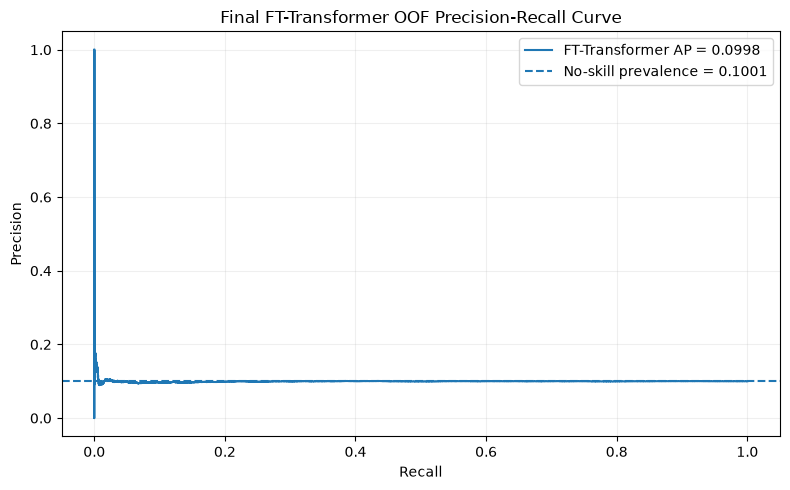

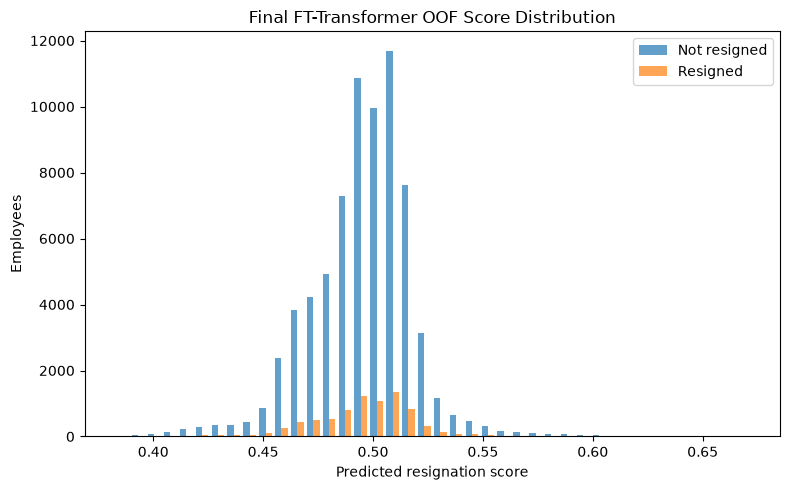

In [12]:
# -----------------------------
# 12. Final probability diagnostics and figures
# -----------------------------

probabilities = oof_predictions["y_probability"]

probability_summary = pd.DataFrame(
    {
        "Statistic": [
            "Minimum",
            "1st percentile",
            "25th percentile",
            "Median",
            "Mean",
            "75th percentile",
            "99th percentile",
            "Maximum",
        ],
        "Probability": [
            probabilities.min(),
            probabilities.quantile(0.01),
            probabilities.quantile(0.25),
            probabilities.median(),
            probabilities.mean(),
            probabilities.quantile(0.75),
            probabilities.quantile(0.99),
            probabilities.max(),
        ],
    }
)

display(probability_summary.round(6))

# FINAL_ES_DIR was selected in the evaluation cell: canonical saved evidence or a new deliberate rerun.

precision, recall, _ = precision_recall_curve(
    oof_predictions["y_true"],
    oof_predictions["y_probability"],
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    recall,
    precision,
    label=f"FT-Transformer AP = {pooled_metrics['average_precision']:.4f}",
)
ax.axhline(
    prevalence,
    linestyle="--",
    label=f"No-skill prevalence = {prevalence:.4f}",
)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Final FT-Transformer OOF Precision-Recall Curve")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()

pr_curve_path = (
    FINAL_ES_DIR / "figure_01_final_ft_transformer_precision_recall_curve.png"
)
if RUN_FT_TRAINING:
    fig.savefig(pr_curve_path, dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(
    [
        oof_predictions.loc[
            oof_predictions["y_true"] == 0,
            "y_probability",
        ],
        oof_predictions.loc[
            oof_predictions["y_true"] == 1,
            "y_probability",
        ],
    ],
    bins=40,
    label=["Not resigned", "Resigned"],
    alpha=0.7,
)
ax.set_xlabel("Predicted resignation score")
ax.set_ylabel("Employees")
ax.set_title("Final FT-Transformer OOF Score Distribution")
ax.legend()
fig.tight_layout()

probability_plot_path = (
    FINAL_ES_DIR / "figure_02_final_ft_transformer_oof_score_distribution.png"
)
if RUN_FT_TRAINING:
    fig.savefig(probability_plot_path, dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# -----------------------------
# 13. Save final weighted + early-stopping artifacts
# -----------------------------

# Historical files are read-only; deliberate reruns use the new directory above.

oof_path = FINAL_ES_DIR / "ft_transformer_final_oof_predictions.csv"
fold_metrics_path = FINAL_ES_DIR / "ft_transformer_final_fold_metrics.csv"
summary_path = FINAL_ES_DIR / "ft_transformer_final_summary_metrics.json"
config_path = FINAL_ES_DIR / "ft_transformer_final_configuration.json"
metadata_path = FINAL_ES_DIR / "ft_transformer_final_run_metadata.json"

if RUN_FT_TRAINING:
    oof_predictions.to_csv(oof_path, index=False)
    fold_metrics.to_csv(fold_metrics_path, index=False)

    with open(summary_path, "w", encoding="utf-8") as file:
        json.dump(final_ft_cv_result.summary_metrics, file, indent=4, default=float)

    with open(config_path, "w", encoding="utf-8") as file:
        json.dump(final_run_params, file, indent=4, default=float)

    run_metadata = {
        "model": model_name,
        "model_id": model_id,
        "experiment": "FT02_weighted_rerun",
        "run_id": FINAL_ES_DIR.name,
        "evaluation_scope": "fixed_FT02_five_fold_development_OOF",
        "candidate_search_executed": False,
        "evaluated_candidate_ids": ["FT02"],
        "metadata_provenance": "Captured from fitted adapters by the shared runner",
        "adapter_metadata": final_ft_cv_result.metadata,
        **{key: final_ft_cv_result.metadata[key] for key in (
            "class_weighting", "refit_outer_train", "fitted_on_all_outer_rows",
            "final_fit_strategy", "final_fit_partition", "best_weights_restored",
            "selection_checkpoint_used_for_final_predictions",
            "selection_learning_rate_scheduler", "final_fit_learning_rate_scheduler",
        )},
        "feature_count": len(primary_model_features),
        "features": primary_model_features,
        "categorical_features": categorical_feature_names,
        "numerical_features": numerical_feature_names,
        "development_rows": len(development_data),
        "formal_holdout_rows_used": 0,
        "outer_cv_folds": [1, 2, 3, 4, 5],
        "candidate_id": final_ft_cv_result.metadata["candidate_id"],
        "inner_validation_fraction": final_run_params["validation_fraction_inner"],
        "maximum_epochs": final_run_params["max_epochs"],
        "patience": final_run_params["patience"],
        "device": device_label,
        "torch_version": torch.__version__,
        "torch_cuda_runtime": torch.version.cuda,
        "cuda_available": bool(torch.cuda.is_available()),
        "executed_params": final_run_params,
        "pooled_pr_auc": final_ft_cv_result.summary_metrics[
            "pooled_average_precision"
        ],
        "pooled_roc_auc": final_ft_cv_result.summary_metrics[
            "pooled_roc_auc"
        ],
        "elapsed_minutes": final_cv_elapsed / 60,
    }

    with open(metadata_path, "w", encoding="utf-8") as file:
        json.dump(run_metadata, file, indent=4, default=float)

else:
    print("Loaded canonical artifacts read-only; no result files rewritten.")

saved_files = [
    oof_path,
    fold_metrics_path,
    summary_path,
    config_path,
    metadata_path,
    pr_curve_path,
    probability_plot_path,
]

assert all(path.exists() for path in saved_files)

print("Final FT-Transformer artifacts saved:")
for path in saved_files:
    print(" ✓", path.name, f"({path.stat().st_size:,} bytes)")

Loaded canonical artifacts read-only; no result files rewritten.
Final FT-Transformer artifacts saved:
 ✓ ft_transformer_final_oof_predictions.csv (3,763,289 bytes)
 ✓ ft_transformer_final_fold_metrics.csv (1,373 bytes)
 ✓ ft_transformer_final_summary_metrics.json (837 bytes)
 ✓ ft_transformer_final_configuration.json (556 bytes)
 ✓ ft_transformer_final_run_metadata.json (3,617 bytes)
 ✓ figure_01_final_ft_transformer_precision_recall_curve.png (39,115 bytes)
 ✓ figure_02_final_ft_transformer_oof_score_distribution.png (34,878 bytes)


In [14]:
# -----------------------------
# 14. Review preserved tuning and baseline evidence
# -----------------------------

TUNING_DIR = FINAL_ES_DIR / "tuning"
tuning_summary_path = TUNING_DIR / "final_tuning_summary.csv"

if tuning_summary_path.exists():
    tuning_summary = pd.read_csv(tuning_summary_path)
    print("Preserved tuning summary:")
    display(tuning_summary)
else:
    print(
        "Tuning summary artifact is not present in this checkout. "
        "The recorded screening decisions are documented above."
    )

print("\nHistorical artifact directories:")
for directory_name in [
    "unweighted_baseline",
    "weighted_fixed_baseline",
    "weighted_early_stopping_final",
]:
    path = RESULTS_DIR / directory_name
    print(
        f" - {directory_name}:",
        "present" if path.exists() else "not present",
    )


Tuning summary artifact is not present in this checkout. The recorded screening decisions are documented above.

Historical artifact directories:
 - unweighted_baseline: present
 - weighted_fixed_baseline: present
 - weighted_early_stopping_final: present


In [15]:
# -----------------------------
# 15. Final integrity and consistency checks
# -----------------------------

assert len(oof_predictions) == 80_000
assert oof_predictions["Employee_ID"].nunique() == 80_000
assert set(oof_predictions["Employee_ID"]).isdisjoint(holdout_ids)
assert oof_predictions["y_probability"].between(0, 1).all()
assert oof_predictions["y_probability"].notna().all()
assert set(oof_predictions["cv_fold"].unique()) == {1, 2, 3, 4, 5}

assert len(fold_metrics) == 5
assert set(fold_metrics["fold"]) == {1, 2, 3, 4, 5}

assert np.isclose(
    pooled_metrics["average_precision"],
    final_ft_cv_result.summary_metrics["pooled_average_precision"],
)
assert np.isclose(
    pooled_metrics["roc_auc"],
    final_ft_cv_result.summary_metrics["pooled_roc_auc"],
)
assert np.isclose(
    pooled_metrics["brier_score"],
    final_ft_cv_result.summary_metrics["pooled_brier_score"],
)

expected_final_params = {
    "learning_rate": 0.001,
    "d_block": 64,
    "n_blocks": 3,
    "ffn_d_hidden": 128,
    "attention_n_heads": 4,
    "ffn_dropout": 0.1,
    "attention_dropout": 0.1,
    "residual_dropout": 0.0,
    "max_epochs": 100,
    "patience": 15,
    "validation_fraction_inner": 0.15,
    "seed": 42,
    "weighting": "dynamic_ratio",
}

for key, expected_value in expected_final_params.items():
    assert final_run_params[key] == expected_value, (
        f"{key}: expected {expected_value}, "
        f"found {final_run_params[key]}"
    )

required_final_artifacts = [
    oof_path,
    fold_metrics_path,
    summary_path,
    config_path,
    metadata_path,
]
missing_artifacts = [
    str(path)
    for path in required_final_artifacts
    if not path.exists()
]
assert not missing_artifacts, f"Missing final artifacts: {missing_artifacts}"

print("All final FT-Transformer integrity checks passed.")
print("80,000 development OOF predictions verified.")
print("Formal holdout remains untouched.")
print("Final development result is ready for cross-model comparison.")


All final FT-Transformer integrity checks passed.
80,000 development OOF predictions verified.
Formal holdout remains untouched.
Final development result is ready for cross-model comparison.


## FT-Transformer Conclusion

The canonical **FT02_20261003T025004Z GPU run** evaluates all 17 approved predictors on the frozen five development folds, with zero formal-holdout use. Pooled **AP is 0.099842**, **ROC-AUC is 0.498905**, **F1 at 0.50 is 0.164071**, and **Brier score is 0.247200**; elapsed runtime was **8.52 minutes**.

AP is close to development prevalence (approximately 0.1001), and ROC-AUC is close to 0.50. Dynamic class weighting affects score scale and threshold behavior, but this run provides no meaningful ranking improvement. Its Brier score is substantially worse than the constant-prevalence reference; weighted scores should not be treated as calibrated resignation probabilities.

Inner validation selected an epoch count for fixed FT02; the final model in each outer fold was trained fresh on inner-training rows only. This completed scope is supported by the earlier descriptive architecture/learning-rate screening and paired preprocessing sensitivity exercise. It does not establish the result of an eight-candidate nested search, and its tuning/refit protocol differs from other models in the group comparison.

The GPU run is the principal FT development input in `configs/analysis_registry.yaml`. Earlier weighted/unweighted results remain historical comparisons. New deliberate training writes a separate run and requires an explicit registry decision before adoption. The formal holdout remains locked.

## Current evidence status

**Completed:** fixed FT02 GPU five-fold development OOF, saved-artifact validation, historical screening and paired preprocessing sensitivity evidence. Ordinary Restart/Run All uses `RUN_FT_TRAINING=False` to load the explicitly selected GPU run read-only, including on a CPU-only kernel.

**Optional extension, not executed:** the eight-candidate config-driven search and full outer-training refit. They are outside this notebook's completed declared scope. The original GPU run lacks per-fold adapter diagnostics; this limitation is disclosed rather than reconstructed as measured evidence. Future training exports actual per-fold adapter metadata. No full experiment or holdout evaluation is launched by the saved default.